This File will contain the model and data cleaning for my final project.
Author: Harry Pearson

First I will import the data from the 2 different csv files, and create one dataframe from it

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
import tensorflow.keras as keras
import tensorflow.keras.layers as layers
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error


Data import and cleaning

In [3]:
df1 = pd.read_csv("noaa_nh_teleconnection_indices.csv")
df1.head()

,Year,Month,NAO,EA,WP,EP_NP,PNA,EA_WR,SCA,TNH,POL,PT,Explained_Variance_Pct
0,1950,1,0.56,-2.71,-1.69,0.91,-3.65,2.29,0.78,0.55,-0.71,NaN,86.0
1,1950,2,0.01,0.66,-1.36,-1.13,-1.69,-0.57,-0.94,-1.07,1.25,NaN,58.6
2,1950,3,-0.78,0.82,-0.38,-0.02,-0.06,-1.80,-0.22,NaN,0.78,NaN,54.3
3,1950,4,0.65,0.28,-0.50,-1.87,-0.23,-2.50,0.46,NaN,0.10,NaN,64.8
4,1950,5,-0.50,-0.51,0.23,-0.98,-0.40,1.41,0.28,NaN,0.55,NaN,49.6


In [4]:
df2 = pd.read_csv("Dillion_Precipitation_label_data.csv")
df2.head()

,DILLON 1 E,PRECIPITATION
0,1/1/2000,0
1,1/2/2000,0.03
2,1/3/2000,0.02
3,1/4/2000,0
4,1/5/2000,0.04


Because Im only interested in data from 1/1/2000 and on, I will need to trim some of the results

In [5]:
df1.drop(df1[df1["Year"] < 2000].index, inplace=True)
df1.head()


,Year,Month,NAO,EA,WP,EP_NP,PNA,EA_WR,SCA,TNH,POL,PT,Explained_Variance_Pct
600,2000,1,0.19,-1.97,-0.21,-0.92,-1.70,0.65,-1.02,-0.11,-0.18,NaN,46.6
601,2000,2,1.48,0.41,-0.41,-0.55,1.20,0.10,-1.16,-0.16,-1.55,NaN,61.3
602,2000,3,0.40,-0.68,0.01,-0.40,0.95,-1.13,-0.92,NaN,-1.52,NaN,61.9
603,2000,4,-0.18,0.33,-1.30,0.08,-0.58,-0.95,0.34,NaN,-0.29,NaN,45.7
604,2000,5,1.52,0.20,-1.46,-0.62,-0.16,0.96,0.27,NaN,-0.24,NaN,71.1


As well because some of the data is monthly, and some of it is daily, I will need to aggregate the daily data into a monthly measurement

In [6]:
df2["DILLON 1 E"] = pd.to_datetime(df2["DILLON 1 E"])
# Treat trace precipitation ("T") as 0 and missing readings ("M") as NaN.
df2["PRECIPITATION"] = df2["PRECIPITATION"].replace({"T": 0, "M": np.nan})
df2["PRECIPITATION"] = pd.to_numeric(df2["PRECIPITATION"], errors="raise")

df2 = (
    df2.assign(
        Year=df2["DILLON 1 E"].dt.year,
        Month=df2["DILLON 1 E"].dt.month,
    )
    .groupby(["Year", "Month"], as_index=False)["PRECIPITATION"]
    .sum(min_count=1)
    .rename(columns={"PRECIPITATION": "Monthly_Precipitation"})
)

df2.head()

,Year,Month,Monthly_Precipitation
0,2000,1,1.48
1,2000,2,1.19
2,2000,3,0.98
3,2000,4,1.76
4,2000,5,1.07


Now for some descriptive statistics on the data

In [7]:
#this describe() doesn't really explain much to us as it is a summary of the data, but it does show us what the model will be working with to make its predicitions.
#all in all it is just to look at whats going on under the hood, and to make sure that the data is in a good state to be used for training.
df1.describe()

,Year,Month,NAO,EA,WP,EP_NP,PNA,EA_WR,SCA,TNH,POL,PT,Explained_Variance_Pct
count,322.000000,322.000000,322.000000,322.000000,322.000000,296.000000,322.000000,322.000000,322.000000,80.000000,322.000000,54.000000,322.000000
mean,2012.919255,6.468944,-0.059472,0.480807,-0.060528,-0.209189,-0.003913,-0.302826,-0.082826,0.300500,-0.250901,0.340370,58.909938
std,7.757200,3.445250,1.062659,1.050854,1.046344,1.052834,0.975312,1.092675,0.969358,0.963729,0.995715,1.039717,13.873479
min,2000.000000,1.000000,-3.140000,-2.070000,-2.530000,-2.750000,-2.850000,-3.430000,-2.690000,-2.870000,-3.230000,-1.550000,19.500000
25%,2006.000000,3.250000,-0.727500,-0.187500,-0.770000,-0.925000,-0.647500,-1.017500,-0.710000,-0.280000,-0.925000,-0.497500,50.225000
50%,2013.000000,6.000000,-0.005000,0.520000,-0.025000,-0.270000,-0.005000,-0.350000,-0.140000,0.200000,-0.240000,0.330000,58.850000
75%,2020.000000,9.000000,0.690000,1.197500,0.690000,0.470000,0.675000,0.460000,0.570000,1.055000,0.370000,1.040000,69.175000
max,2026.000000,12.000000,2.550000,3.670000,2.500000,3.360000,2.150000,4.030000,2.480000,2.200000,2.580000,2.460000,90.000000


In [8]:
#this df2.describe() doesn't really explain much in the grand scheme of things, but it does show that there are some months with no precipitation data. 
#this can happen for 1 of 2 reasons: either there was no precipitation that month, or the data was not recorded. The first case is fine, but the second case is a problem.
#as there is no way to know which months had no precipitation and which months had missing data, we will have to move forward with the assumption that all months with no precipitation data are months with no precipitation. 
#This is not ideal, but it is the best we can do with the data we have.
df2.describe()

,Year,Month,Monthly_Precipitation
count,313.000000,313.000000,313.000000
mean,2012.543131,6.482428,1.261118
std,7.538718,3.466023,0.775216
min,2000.000000,1.000000,0.000000
25%,2006.000000,3.000000,0.700000
50%,2013.000000,6.000000,1.060000
75%,2019.000000,9.000000,1.660000
max,2026.000000,12.000000,4.650000


In [9]:
df1.isnull().sum()/df1.shape[0]

Year                      0.000000
Month                     0.000000
NAO                       0.000000
EA                        0.000000
WP                        0.000000
EP_NP                     0.080745
PNA                       0.000000
EA_WR                     0.000000
SCA                       0.000000
TNH                       0.751553
POL                       0.000000
PT                        0.832298
Explained_Variance_Pct    0.000000
dtype: float64

In [10]:
df2.isnull().sum()/df2.shape[0]

Year                     0.0
Month                    0.0
Monthly_Precipitation    0.0
dtype: float64

We can see here that the columns of TNH(Tropical / Northern Hemishpere Pattern) and PT(Pacific Transition Pattern) are missing 75% and 83% of their data respectively. with this amount of missing data, this feature column can do nothing but hurt, and there is no way to accuratly impute the data, as such, I will drop the entire feature.

In [11]:
df1.drop(columns=["TNH", "PT"], inplace=True)
df1.head()

,Year,Month,NAO,EA,WP,EP_NP,PNA,EA_WR,SCA,POL,Explained_Variance_Pct
600,2000,1,0.19,-1.97,-0.21,-0.92,-1.70,0.65,-1.02,-0.18,46.6
601,2000,2,1.48,0.41,-0.41,-0.55,1.20,0.10,-1.16,-1.55,61.3
602,2000,3,0.40,-0.68,0.01,-0.40,0.95,-1.13,-0.92,-1.52,61.9
603,2000,4,-0.18,0.33,-1.30,0.08,-0.58,-0.95,0.34,-0.29,45.7
604,2000,5,1.52,0.20,-1.46,-0.62,-0.16,0.96,0.27,-0.24,71.1


Beyond that, we see that the EP_NP (Eastern Pacific/ Northern Pacific Patern) is missing 8% of it's data, however, I believe that this is a small enough value that we can impute the data with minimal impact to the models accuracy.

In [12]:
ep_np_imputer = SimpleImputer(strategy="median")
df1[["EP_NP"]] = ep_np_imputer.fit_transform(df1[["EP_NP"]])
df1.isnull().sum()/df1.shape[0]

Year                      0.0
Month                     0.0
NAO                       0.0
EA                        0.0
WP                        0.0
EP_NP                     0.0
PNA                       0.0
EA_WR                     0.0
SCA                       0.0
POL                       0.0
Explained_Variance_Pct    0.0
dtype: float64

From the previous actions, we can see that all the missing values have been dealt with, the timeframe for the 2 dataframes has been matched, and the data is ready to go, so now I will combine them into a single structure to start working with the model itself.

In [13]:
df = pd.merge(df1, df2, how="inner", on=["Year", "Month"])
df.head()

,Year,Month,NAO,EA,WP,EP_NP,PNA,EA_WR,SCA,POL,Explained_Variance_Pct,Monthly_Precipitation
0,2000,1,0.19,-1.97,-0.21,-0.92,-1.70,0.65,-1.02,-0.18,46.6,1.48
1,2000,2,1.48,0.41,-0.41,-0.55,1.20,0.10,-1.16,-1.55,61.3,1.19
2,2000,3,0.40,-0.68,0.01,-0.40,0.95,-1.13,-0.92,-1.52,61.9,0.98
3,2000,4,-0.18,0.33,-1.30,0.08,-0.58,-0.95,0.34,-0.29,45.7,1.76
4,2000,5,1.52,0.20,-1.46,-0.62,-0.16,0.96,0.27,-0.24,71.1,1.07


now to put it all together

In [14]:
# Double check that everything is in chronological order.
data = df.sort_values(["Year", "Month"]).reset_index(drop=True).copy()

data["Date"] = pd.to_datetime(
    dict(year=data["Year"], month=data["Month"], day=1)
)

feature_cols = [
    c for c in data.columns
    if c not in ["Year", "Month", "Date"]
]

# The precipitation CSV ends on 2026-01-01, so its January total is incomplete.
data = data.iloc[:-1].copy()

# Encode the time of year cyclically; don't use Year as a numeric predictor.
# Also helpful to have a Date column for plotting later.
# as well as precipitation is seasonal, so I would imagine that some cyclic encoding of the month would be helpful to the model, as it would allow it to learn that certain months are more likely to have precipitation than others.
data["Month_sin"] = np.sin(2 * np.pi * data["Month"] / 12)
data["Month_cos"] = np.cos(2 * np.pi * data["Month"] / 12)

target_col = "Monthly_Precipitation"
feature_cols = [c for c in data.columns if c not in ["Year", "Month", "Date"]]
lookback = 12

# Split by time, not randomly. Fit scaling only on the training period.
split_idx = int(len(data) * 0.8)
x_scaler = MinMaxScaler().fit(data.loc[:split_idx - 1, feature_cols])
y_scaler = MinMaxScaler().fit(data.loc[:split_idx - 1, [target_col]])

X_all = x_scaler.transform(data[feature_cols])
y_all = y_scaler.transform(data[[target_col]]).ravel()

Now to build the model itself. in the most simple of terms

In [ ]:
# Each input is 12 months; its label is the following month's precipitation.
def make_sequences(start_target, end_target):
    X, y = [], []
    for target_idx in range(max(lookback, start_target), end_target):
        X.append(X_all[target_idx - lookback:target_idx])
        y.append(y_all[target_idx])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

X_train, y_train = make_sequences(lookback, split_idx)
X_test, y_test = make_sequences(split_idx, len(data))

model0 = keras.Sequential([
    layers.Input(shape=(lookback, len(feature_cols))),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(1),
])

model0.compile(optimizer="adam", loss="mse", metrics=["mae"])

history = model0.fit(
    X_train,
    y_train,
    validation_split=0.2,
    shuffle=False,
    epochs=20,
    batch_size=16,
)

# Convert scaled predictions back to precipitation units.
pred = y_scaler.inverse_transform(model0.predict(X_test, verbose=0)).ravel()
actual = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

# Compare with a simple baseline: predict next month using the previous month's total.
naive = data[target_col].iloc[split_idx - 1:-1].to_numpy()

print("LSTM test MAE:", mean_absolute_error(actual, pred))
print("Previous-month baseline MAE:", mean_absolute_error(actual, naive))



Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0565 - mae: 0.1913 - val_loss: 0.0405 - val_mae: 0.1724
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0456 - mae: 0.1717 - val_loss: 0.0293 - val_mae: 0.1235
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0348 - mae: 0.1400 - val_loss: 0.0270 - val_mae: 0.1266
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0333 - mae: 0.1418 - val_loss: 0.0280 - val_mae: 0.1277
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0356 - mae: 0.1393 - val_loss: 0.0291 - val_mae: 0.1261
Epoch 6/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0306 - mae: 0.1376 - val_loss: 0.0298 - val_mae: 0.1328
Epoch 7/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0328 - mae: 0.1384 - val_loss: 0.0300 - val_mae: 0.1300
Epoch 8/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0317 - mae: 0.1349 - val_loss: 0.0303 - val_mae: 0.1299
Epoch 9/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0304 - mae:

Now to visualize our findings

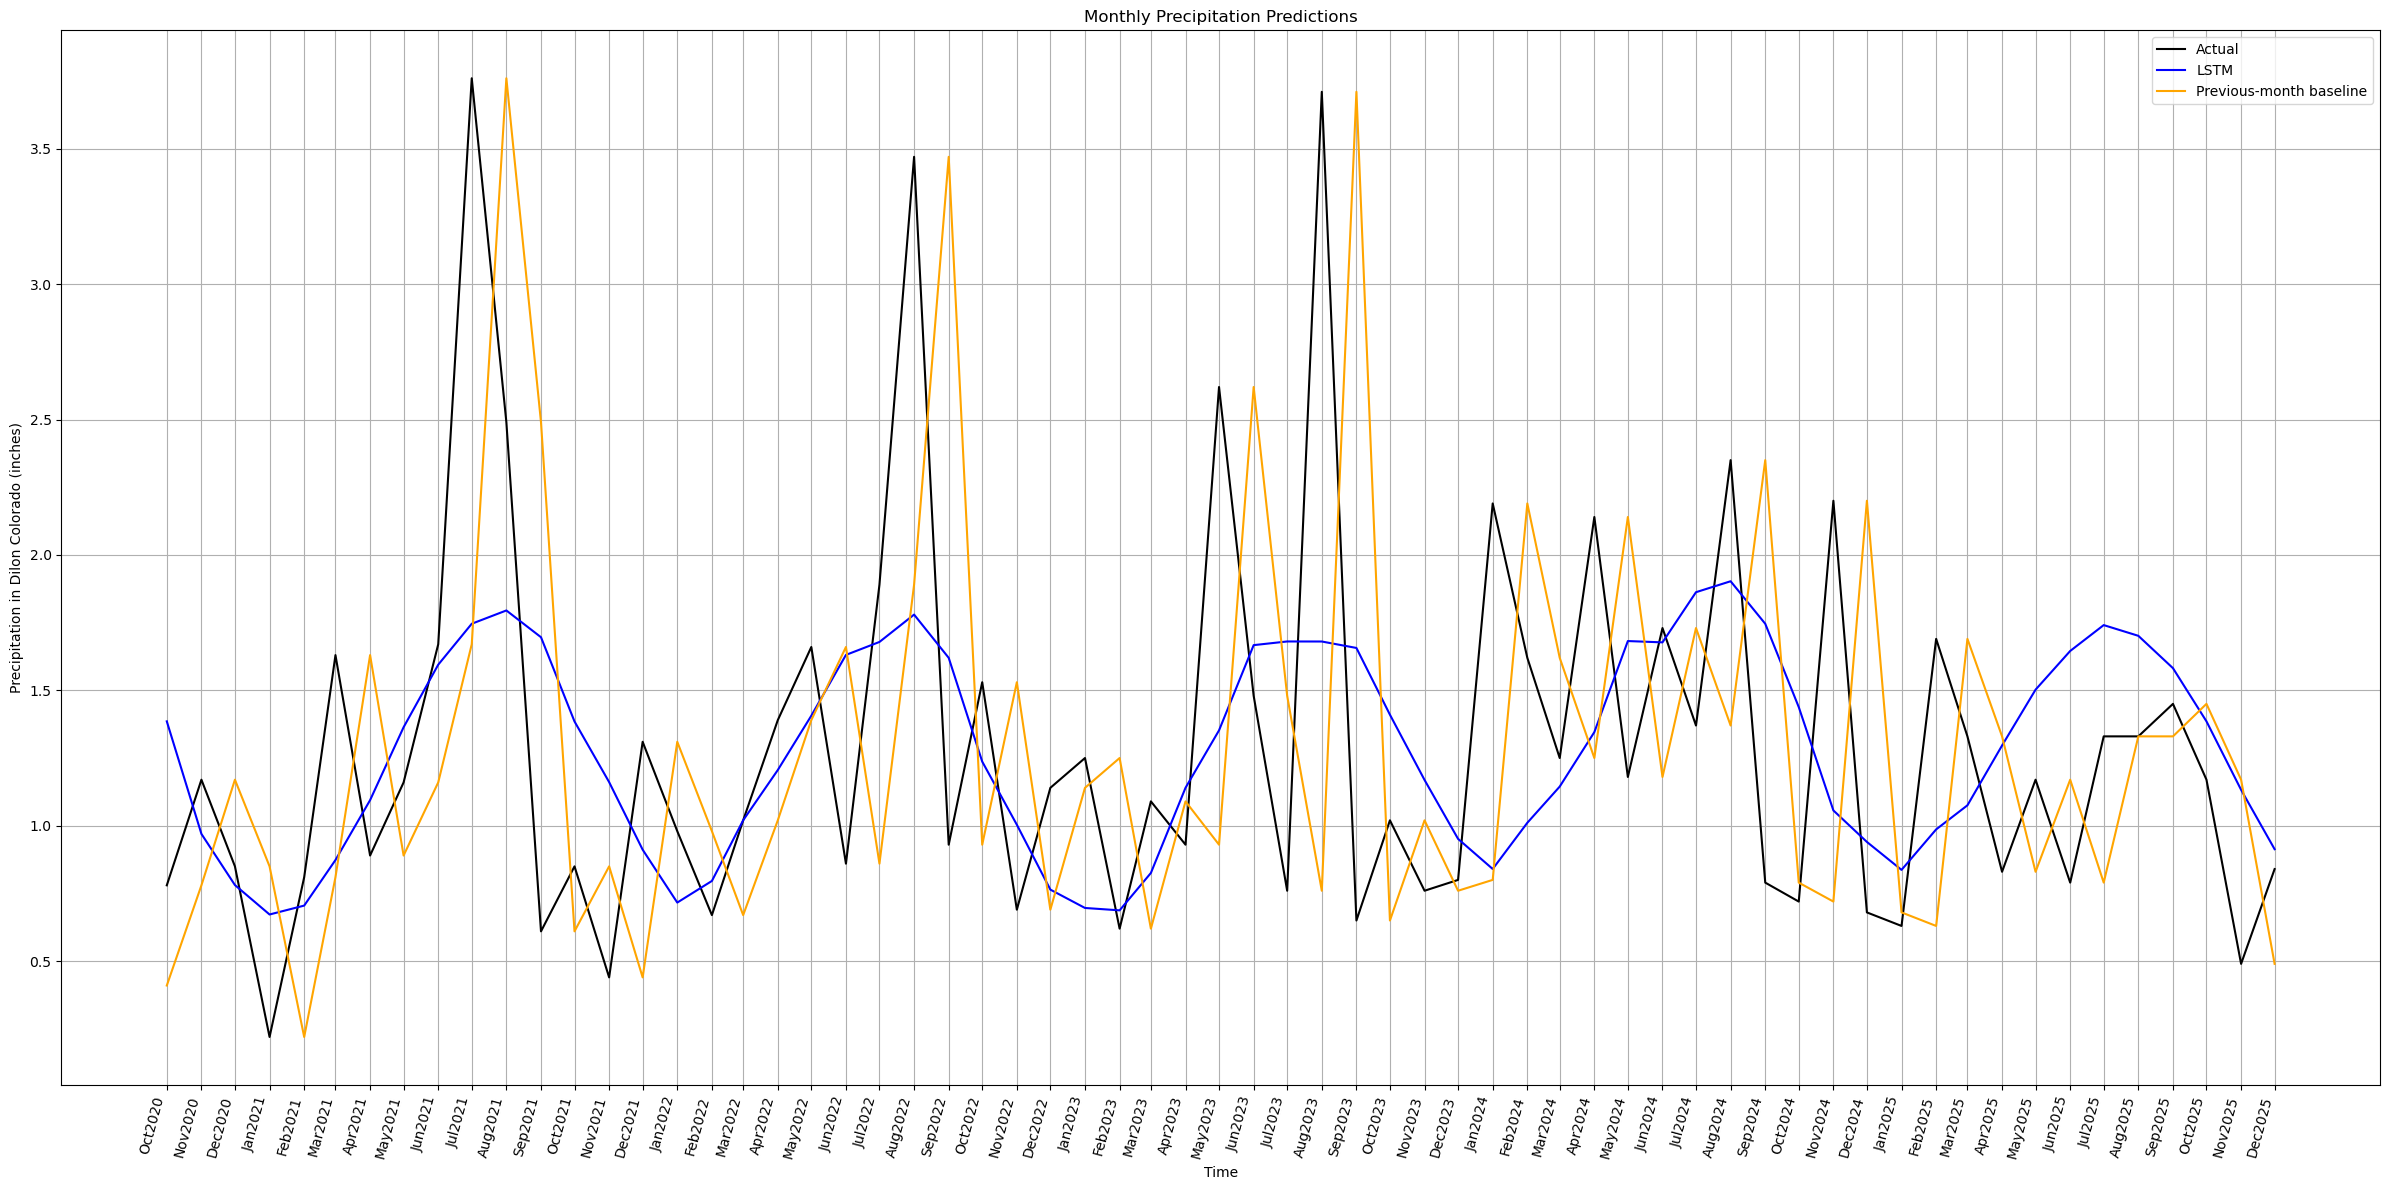

In [16]:
#First we will look at the data itself
#We will plot the actual precipitation data, the LSTM model's predictions, and a naive baseline that predicts the next month's precipitation based on the previous month's total. 
#This will help us visualize how well the model is performing compared to a simple baseline.

fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(data["Date"].iloc[split_idx:], actual, label="Actual", color="black")
ax.plot(data["Date"].iloc[split_idx:], pred, label="LSTM", color="blue")
ax.plot(data["Date"].iloc[split_idx:], naive, label="Previous-month baseline", color="orange")
ax.set_title("Monthly Precipitation Predictions")
ax.set_xlabel("Time")
ax.set_xticks(data["Date"].iloc[split_idx:])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b%Y"))
fig.autofmt_xdate(rotation=75)
ax.set_ylabel("Precipitation in Dilon Colorado (inches)")
ax.legend()
plt.grid()
plt.tight_layout()
plt.show()

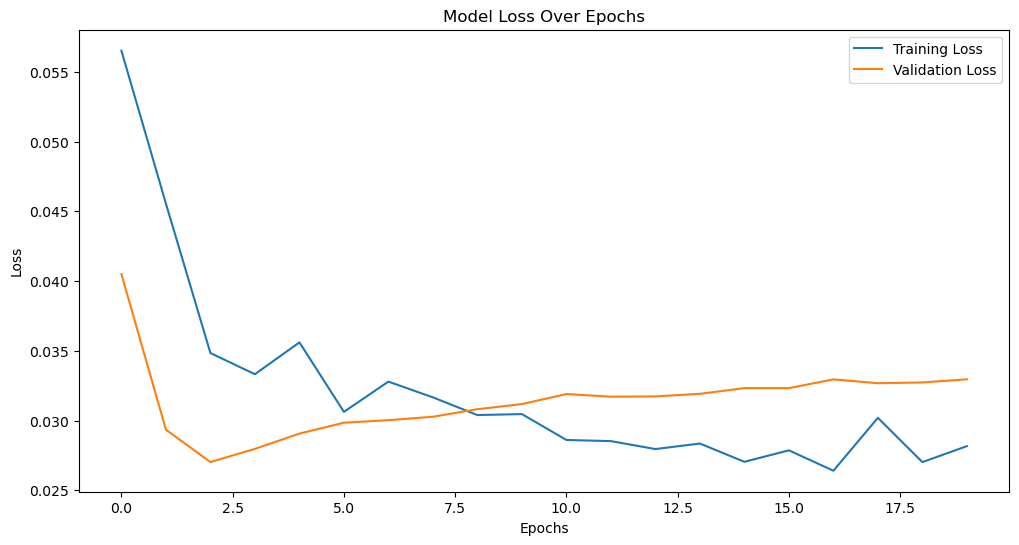

In [17]:
#Now we will plot the training and validation loss over epochs to see how well the model is learning. This will help us identify if the model is overfitting or underfitting the data.
#on top we will also plot the nieve model loss to see how the basic model does in comparison to the LSTM model.
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

From this I think that the model is both a little too simple, and that it is overfit. We can see that the precipitation is a very sharp graph, while our sinle layer LSTM model is very reminiscent of a sin or cos graph. on the other hand, the mondel far outperformed the nieve model, so it is good that it is better than just looking at averages. Lastly we can see that the model is slightly overfit, as the models validation loss starts to increase after 2 epochs.
This will all be addressed now, in my seccond version of the model.

In [18]:
model1 = keras.Sequential([
    layers.Input(shape=(lookback, len(feature_cols))),
    layers.LSTM(32, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),            #Added an aditional LSTM layer to try and learn more complex patterns in the data.
    layers.Dropout(0.2),
    layers.Dense(1),
])

model1.compile(optimizer="adam", loss="mse", metrics=["mae"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history1 = model1.fit(
    X_train,
    y_train,
    validation_split=0.2,
    shuffle=False,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
)

pred1 = y_scaler.inverse_transform(model1.predict(X_test, verbose=0)).ravel()

print("LSTM test MAE:", mean_absolute_error(actual, pred1))

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0367 - mae: 0.1473 - val_loss: 0.0273 - val_mae: 0.1393
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0369 - mae: 0.1444 - val_loss: 0.0261 - val_mae: 0.1281
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0290 - mae: 0.1341 - val_loss: 0.0276 - val_mae: 0.1313
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0289 - mae: 0.1296 - val_loss: 0.0295 - val_mae: 0.1325
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0289 - mae: 0.1293 - val_loss: 0.0312 - val_mae: 0.1351
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0255 - mae: 0.1223 - val_loss: 0.0321 - val_mae: 0.1372
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0277 - mae: 0.1263 - val_loss: 0.0323 - val_mae: 0.1373
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0253 - mae: 0.1222 - val_loss: 0.0323 - val_mae: 0.1361
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.02

Now to graph the results

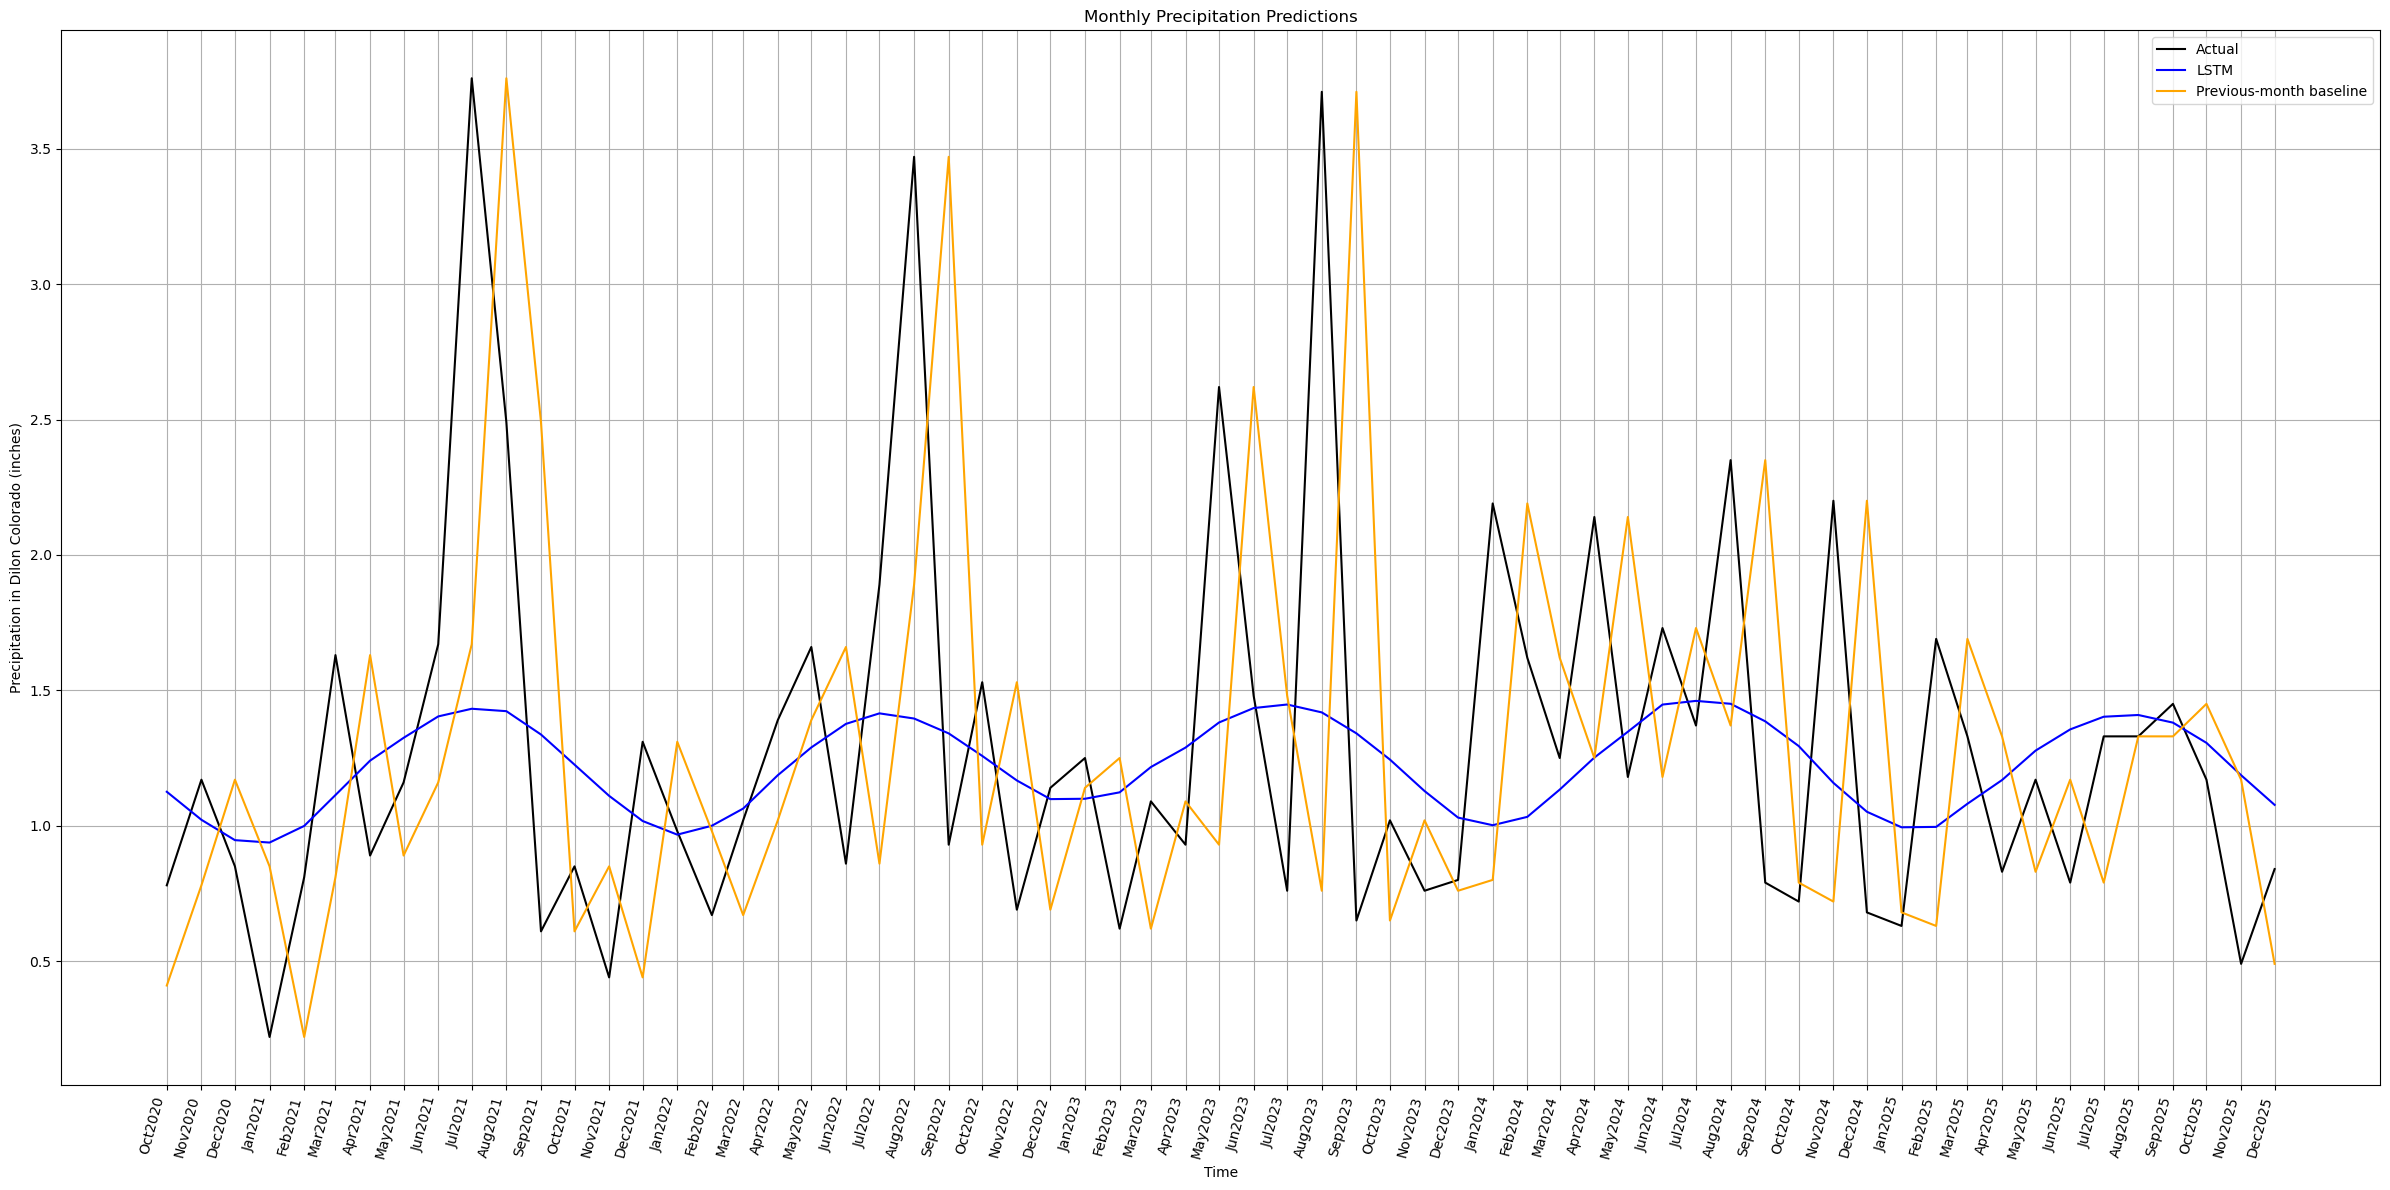

In [19]:
fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(data["Date"].iloc[split_idx:], actual, label="Actual", color="black")
ax.plot(data["Date"].iloc[split_idx:], pred1, label="LSTM", color="blue")
ax.plot(data["Date"].iloc[split_idx:], naive, label="Previous-month baseline", color="orange")
ax.set_title("Monthly Precipitation Predictions")
ax.set_xlabel("Time")
ax.set_xticks(data["Date"].iloc[split_idx:])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b%Y"))
fig.autofmt_xdate(rotation=75)
ax.set_ylabel("Precipitation in Dilon Colorado (inches)")
ax.legend()
plt.grid()
plt.tight_layout()
plt.show()

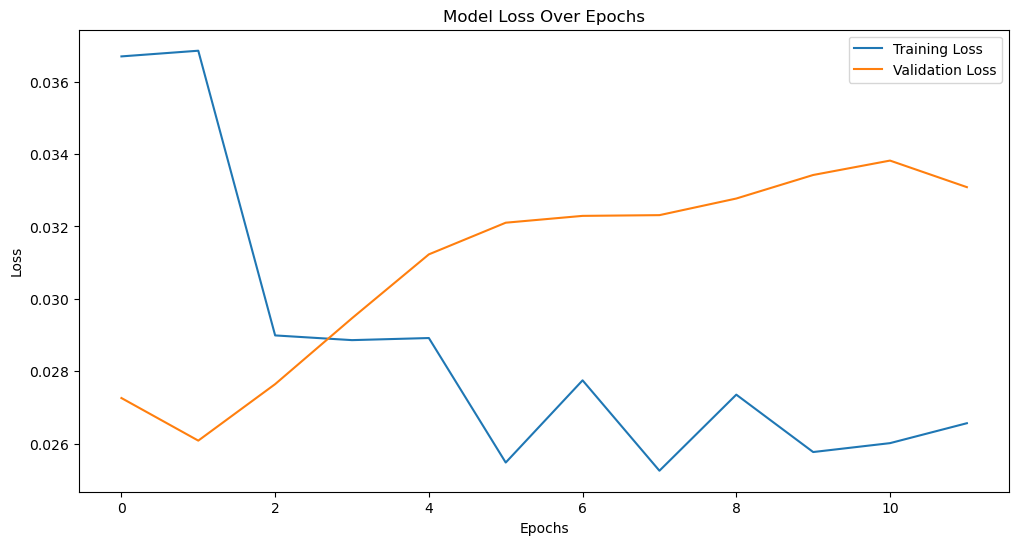

In [20]:
plt.figure(figsize=(12, 6))
plt.plot(history1.history['loss'], label='Training Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

So, by adding a layer and callback to increase complexity and reduce overfitting, we have increased the MAE by .02.. Which to be honest, I did not expect that at all..
By adding an additional layer, the prediction line actually flattened out, rather than staying with the graph.
So what if i add another 3 for significantly increased complexity?

In [21]:
model2 = keras.Sequential([
    layers.Input(shape=(lookback, len(feature_cols))),
    layers.LSTM(32, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),            
    layers.Dropout(0.2),
    layers.Dense(1),
])

model2.compile(optimizer="adam", loss="mse", metrics=["mae"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history2 = model2.fit(
    X_train,
    y_train,
    validation_split=0.2,
    shuffle=False,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
)

pred2 = y_scaler.inverse_transform(model2.predict(X_test, verbose=0)).ravel()

print("LSTM test MAE:", mean_absolute_error(actual, pred2))

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - loss: 0.0451 - mae: 0.1651 - val_loss: 0.0378 - val_mae: 0.1723
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0385 - mae: 0.1510 - val_loss: 0.0266 - val_mae: 0.1239
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0313 - mae: 0.1364 - val_loss: 0.0278 - val_mae: 0.1428
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0343 - mae: 0.1449 - val_loss: 0.0251 - val_mae: 0.1252
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0309 - mae: 0.1334 - val_loss: 0.0261 - val_mae: 0.1351
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0304 - mae: 0.1382 - val_loss: 0.0258 - val_mae: 0.1293
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0301 - mae: 0.1327 - val_loss: 0.0293 - val_mae: 0.1411
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0290 - mae: 0.1319 - val_loss: 0.0315 - val_mae: 0.1416
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - lo

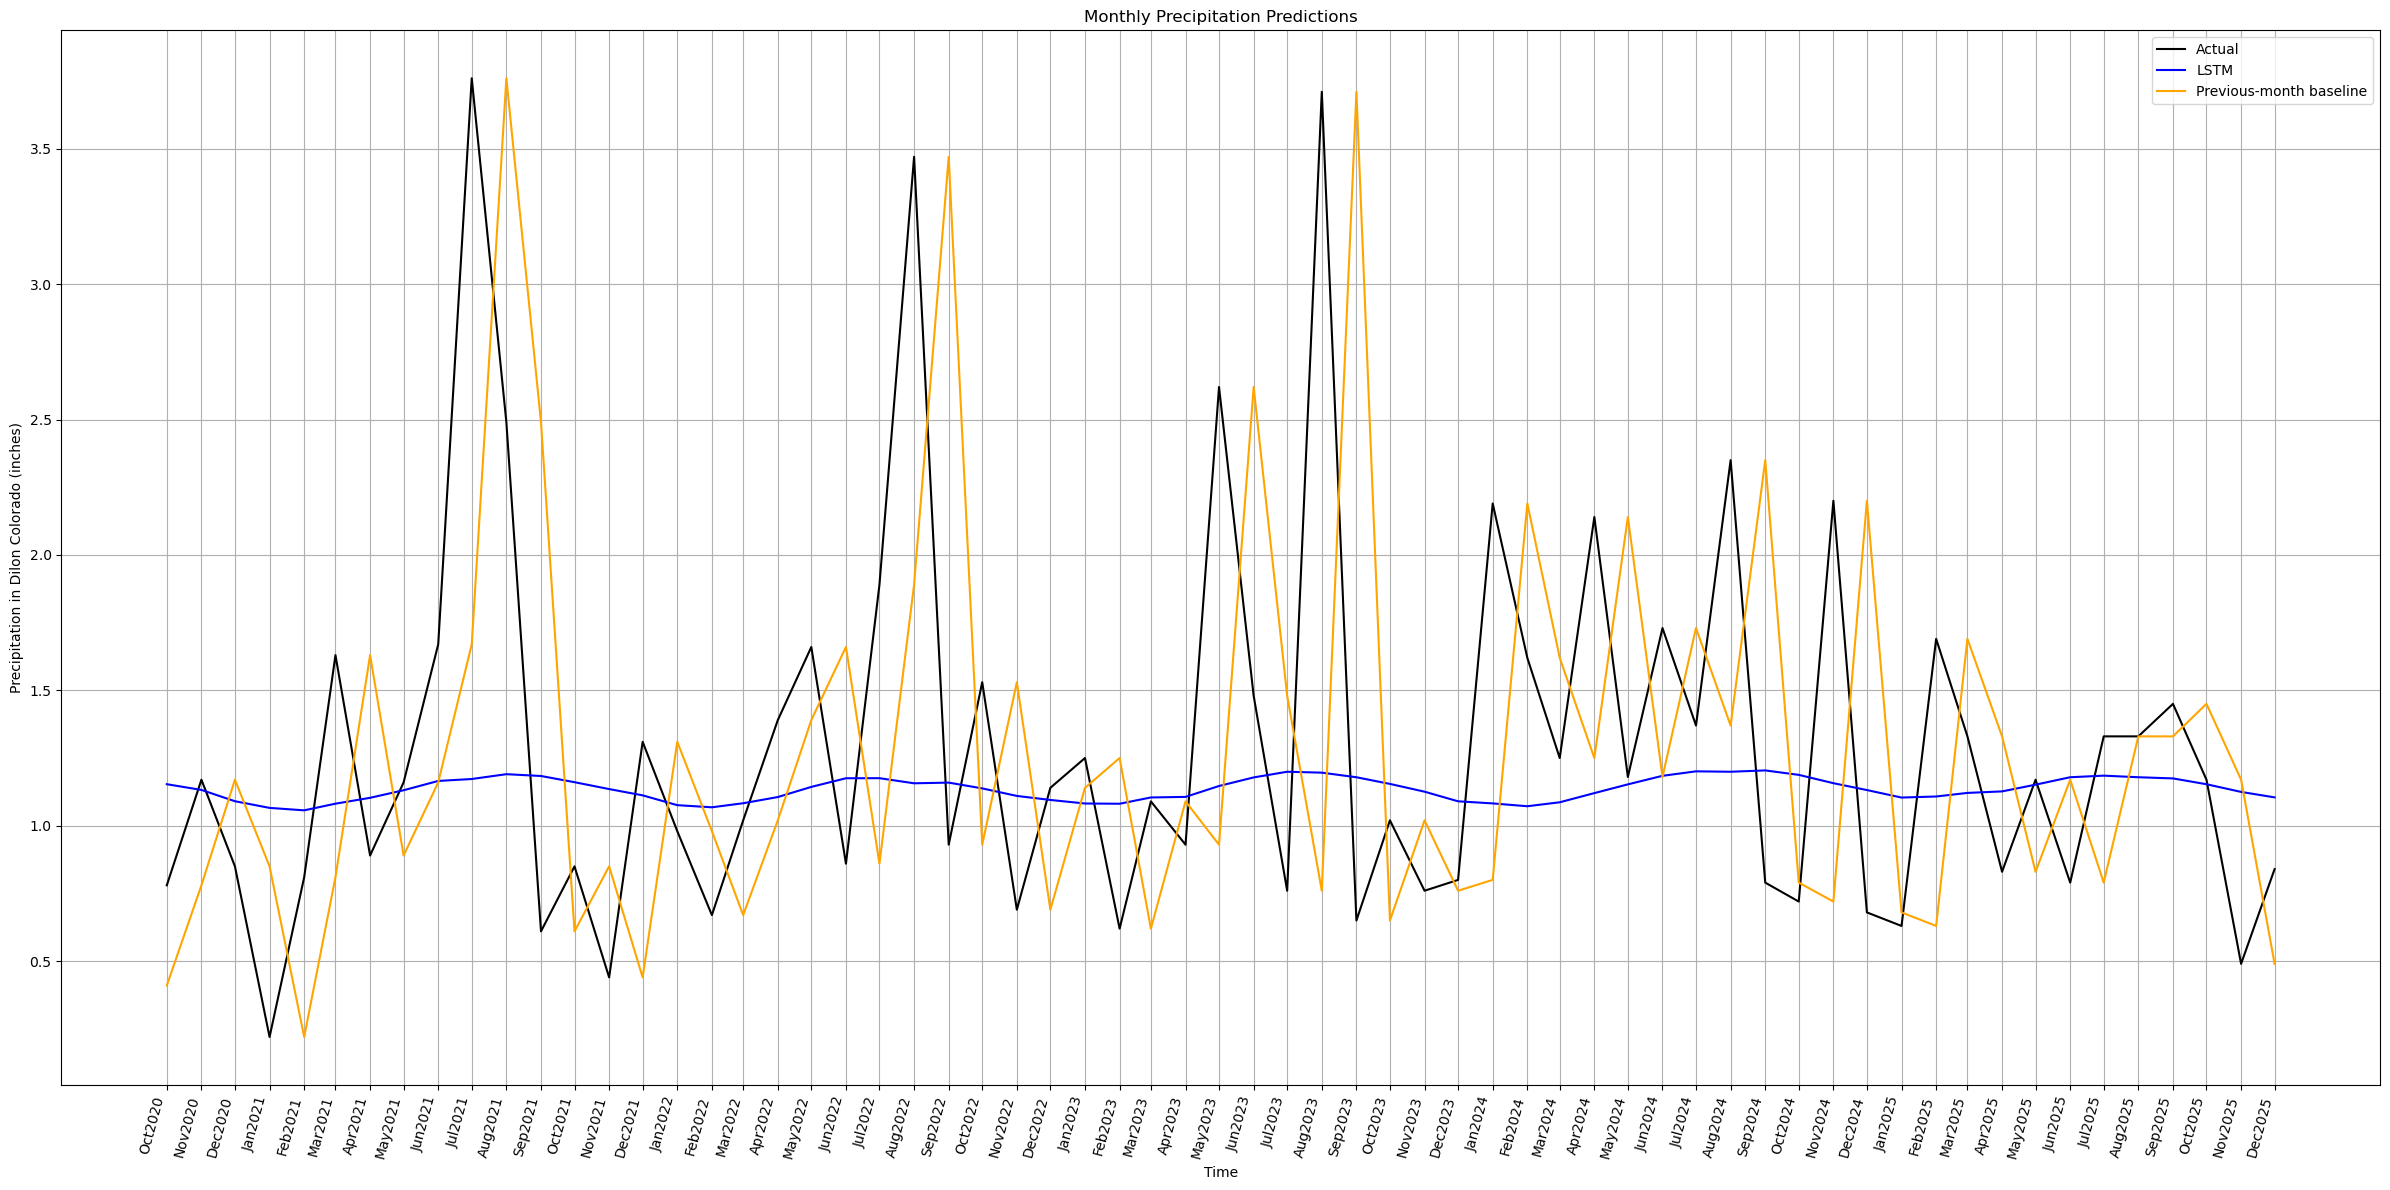

In [22]:
fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(data["Date"].iloc[split_idx:], actual, label="Actual", color="black")
ax.plot(data["Date"].iloc[split_idx:], pred2, label="LSTM", color="blue")
ax.plot(data["Date"].iloc[split_idx:], naive, label="Previous-month baseline", color="orange")
ax.set_title("Monthly Precipitation Predictions")
ax.set_xlabel("Time")
ax.set_xticks(data["Date"].iloc[split_idx:])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b%Y"))
fig.autofmt_xdate(rotation=75)
ax.set_ylabel("Precipitation in Dilon Colorado (inches)")
ax.legend()
plt.grid()
plt.tight_layout()
plt.show()

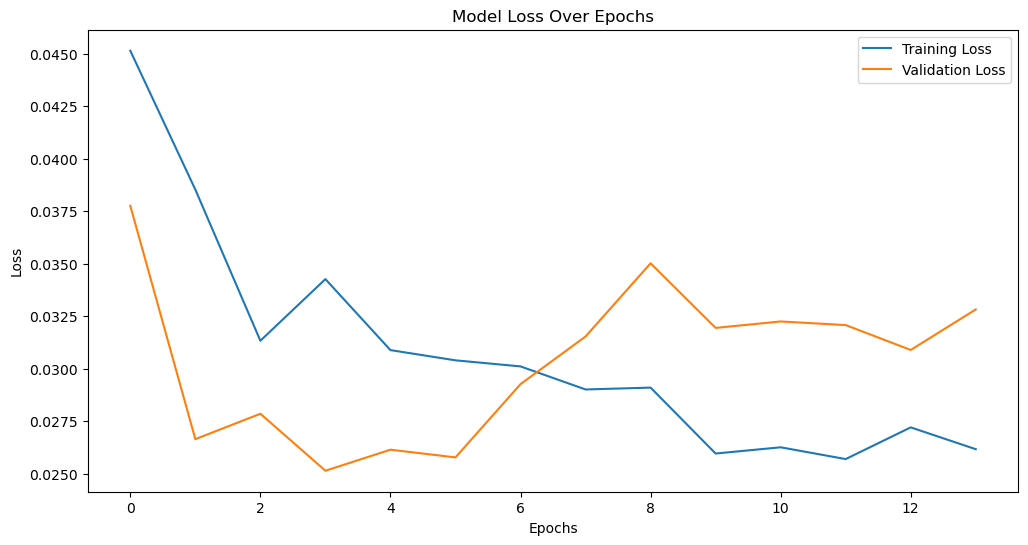

In [23]:
plt.figure(figsize=(12, 6))
plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

This attempt brought our model back to baseline, as the increased complexity just made the prediction line go essentially flat. Which was not the goal at all. This makes me wonder if a neural net is the correct solution to this problem at all. So, just for fun, I'm going to try and put a Forrest Algorythm on it and see how it performs.

In [24]:
from sklearn.ensemble import RandomForestRegressor

# Random forests require 2D inputs, so flatten each (months, features) window.
X_train_rf = X_train.reshape(X_train.shape[0], -1)
X_test_rf = X_test.reshape(X_test.shape[0], -1)

val_idx = int(len(X_train_rf) * 0.8)
X_fit, X_val = X_train_rf[:val_idx], X_train_rf[val_idx:]
y_fit, y_val = y_train[:val_idx], y_train[val_idx:]

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_fit, y_fit)

rf_val_pred = rf_model.predict(X_val)
rf_val_actual = y_scaler.inverse_transform(y_val.reshape(-1, 1)).ravel()
rf_val_pred = y_scaler.inverse_transform(rf_val_pred.reshape(-1, 1)).ravel()
print("Random Forest validation MAE:", mean_absolute_error(rf_val_actual, rf_val_pred))

# Evaluate on the held-out test period; validation data is not used to fit the forest.
rf_pred = y_scaler.inverse_transform(rf_model.predict(X_test_rf).reshape(-1, 1)).ravel()
rf_test_actual = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
print("Random Forest test MAE:", mean_absolute_error(rf_test_actual, rf_pred))


Random Forest validation MAE: 0.635979180530936
Random Forest test MAE: 0.5022793855594531


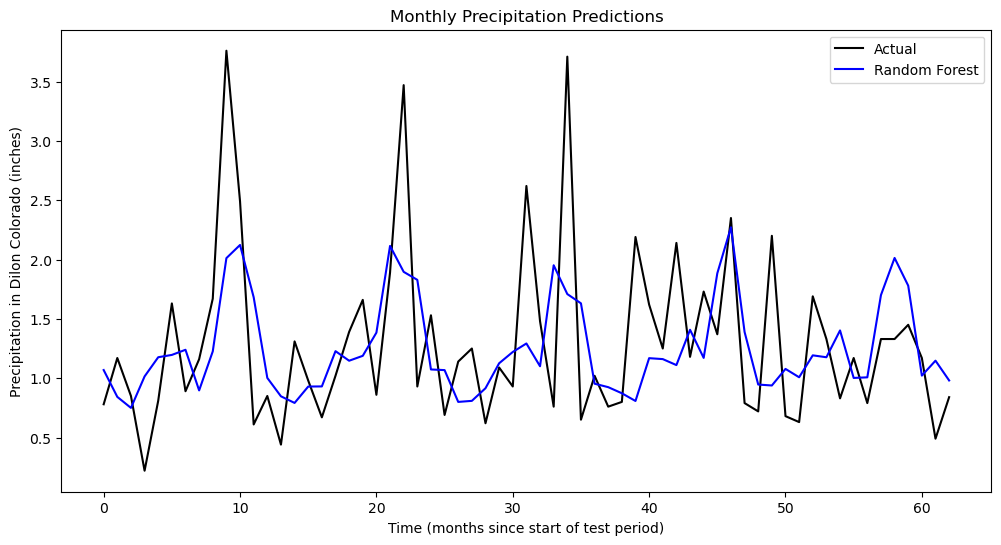

In [25]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(rf_test_actual, label="Actual", color="black")
ax.plot(rf_pred, label="Random Forest", color="blue")
ax.set_title("Monthly Precipitation Predictions")
ax.set_xlabel("Time (months since start of test period)")
ax.set_ylabel("Precipitation in Dilon Colorado (inches)")
ax.legend()
plt.show()


Looking at this graph now, It seems more like something I was expecting, at least in the shape of the line; however, the LSTM model beat this random forrest by .1 on MAE, so a pretty signigicant margin conisdering both NN loss < RFR loss < 0.8.  
All that is to say, our neural net, taking the approach of a more calm cyclical prediction, was better over time than the erratic random forrest regressor.

I will now try to make more accurate predictions by the sharp nature of the data, a lookback of 12 months is a bit excessive, so I will set the lookback to 6 months, rerun similarly built models and see how it does.

In [26]:
lookback = 6

X_train, y_train = make_sequences(lookback, split_idx)
X_test, y_test = make_sequences(split_idx, len(data))

model3 = keras.Sequential([
    layers.Input(shape=(lookback, len(feature_cols))),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(1),
])

model3.compile(optimizer="adam", loss="mse", metrics=["mae"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history3 = model3.fit(
    X_train,
    y_train,
    validation_split=0.2,
    shuffle=False,
    epochs=20,
    batch_size=16,
    callbacks=[early_stop],
)

# Convert scaled predictions back to precipitation units.
pred3 = y_scaler.inverse_transform(model3.predict(X_test, verbose=0)).ravel()
actual = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

# Compare with a simple baseline: predict next month using the previous month's total.
naive = data[target_col].iloc[split_idx - 1:-1].to_numpy()

print("LSTM test MAE:", mean_absolute_error(actual, pred3))
print("Previous-month baseline MAE:", mean_absolute_error(actual, naive))

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.1315 - mae: 0.2847 - val_loss: 0.0338 - val_mae: 0.1598
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0658 - mae: 0.2186 - val_loss: 0.0271 - val_mae: 0.1363
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0432 - mae: 0.1591 - val_loss: 0.0284 - val_mae: 0.1230
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0334 - mae: 0.1378 - val_loss: 0.0267 - val_mae: 0.1278
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0403 - mae: 0.1569 - val_loss: 0.0281 - val_mae: 0.1315
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0371 - mae: 0.1484 - val_loss: 0.0289 - val_mae: 0.1274
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0378 - mae: 0.1497 - val_loss: 0.0296 - val_mae: 0.1294
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0336 - mae: 0.1415 - val_loss: 0.0302 - val_mae: 0.1307
Epoch 9/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0320 - mae:

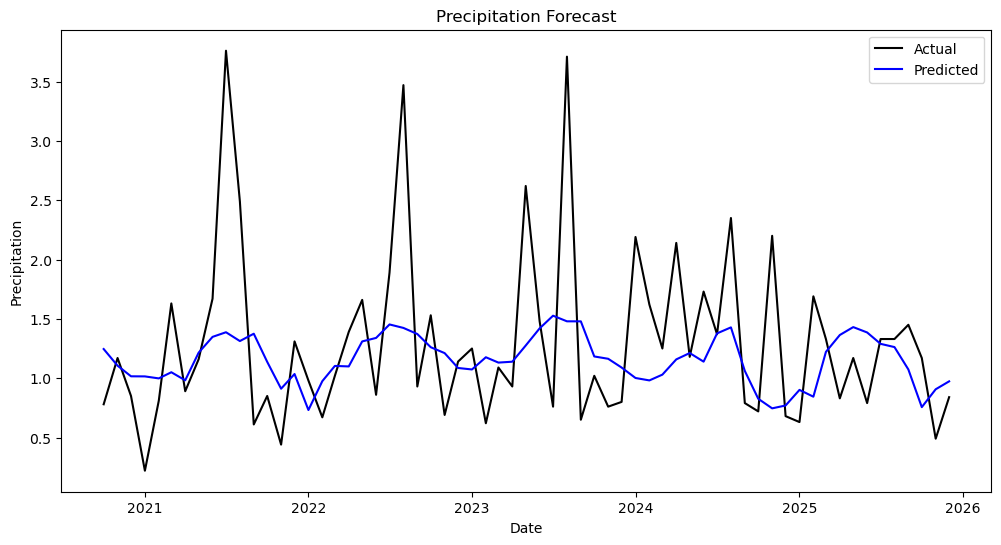

In [27]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(data["Date"].iloc[split_idx:], actual, label="Actual", color="black")
ax.plot(data["Date"].iloc[split_idx:], pred3, label="Predicted", color="blue")
ax.set_title("Precipitation Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Precipitation")
ax.legend()
plt.show()

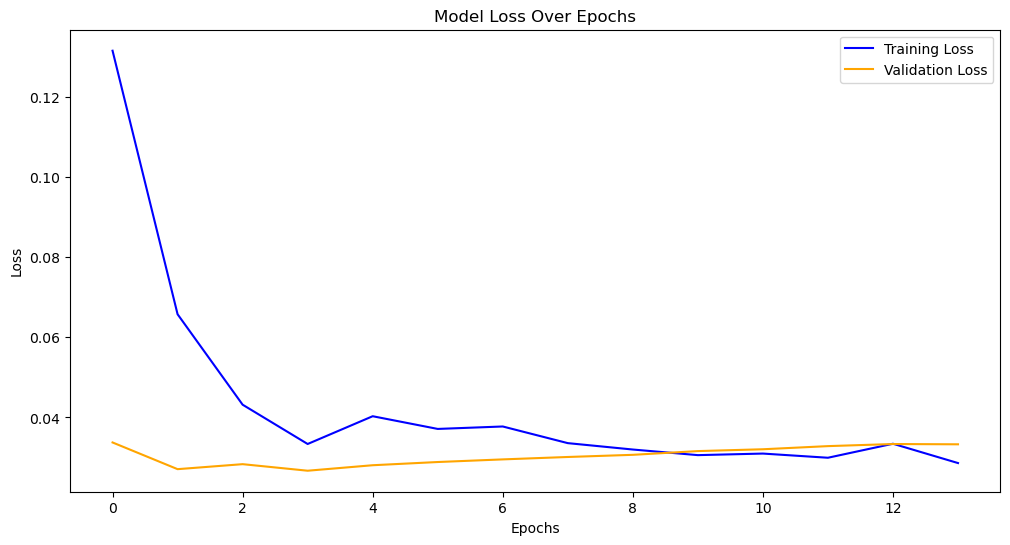

In [28]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(history3.history['loss'], label='Training Loss', color='blue')
ax.plot(history3.history['val_loss'], label='Validation Loss', color='orange')
ax.set_title('Model Loss Over Epochs')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
ax.legend()
plt.show()

This was closer to what I was expecting; however, the longer lookback model1 (the second built model) had a very similar MAE, with a much 'smoother' prediction curve.

In [29]:
model4 = keras.Sequential([
    layers.Input(shape=(lookback, len(feature_cols))),
    layers.LSTM(32, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(1),
])

model4.compile(optimizer="adam", loss="mse", metrics=["mae"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history4 = model4.fit(
    X_train,
    y_train,
    validation_split=0.2,
    shuffle=False,
    epochs=20,
    batch_size=16,
    callbacks=[early_stop],
)

# Convert scaled predictions back to precipitation units.
pred4 = y_scaler.inverse_transform(model4.predict(X_test, verbose=0)).ravel()
actual = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

# Compare with a simple baseline: predict next month using the previous month's total.
naive = data[target_col].iloc[split_idx - 1:-1].to_numpy()

print("LSTM test MAE:", mean_absolute_error(actual, pred4))
print("Previous-month baseline MAE:", mean_absolute_error(actual, naive))

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0501 - mae: 0.1692 - val_loss: 0.0399 - val_mae: 0.1775
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0394 - mae: 0.1641 - val_loss: 0.0247 - val_mae: 0.1238
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0301 - mae: 0.1315 - val_loss: 0.0261 - val_mae: 0.1336
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0297 - mae: 0.1365 - val_loss: 0.0283 - val_mae: 0.1401
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0315 - mae: 0.1378 - val_loss: 0.0274 - val_mae: 0.1314
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0288 - mae: 0.1314 - val_loss: 0.0300 - val_mae: 0.1397
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0280 - mae: 0.1305 - val_loss: 0.0308 - val_mae: 0.1384
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0282 - mae: 0.1274 - val_loss: 0.0331 - val_mae: 0.1444
Epoch 9/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0284 - mae:

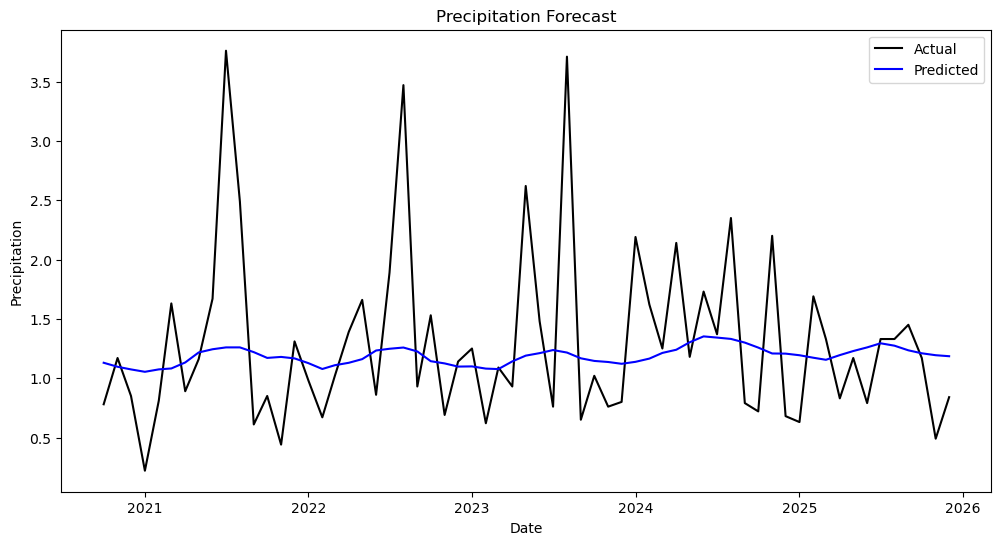

In [30]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(data["Date"].iloc[split_idx:], actual, label="Actual", color="black")
ax.plot(data["Date"].iloc[split_idx:], pred4, label="Predicted", color="blue")
ax.set_title("Precipitation Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Precipitation")
ax.legend()
plt.show()

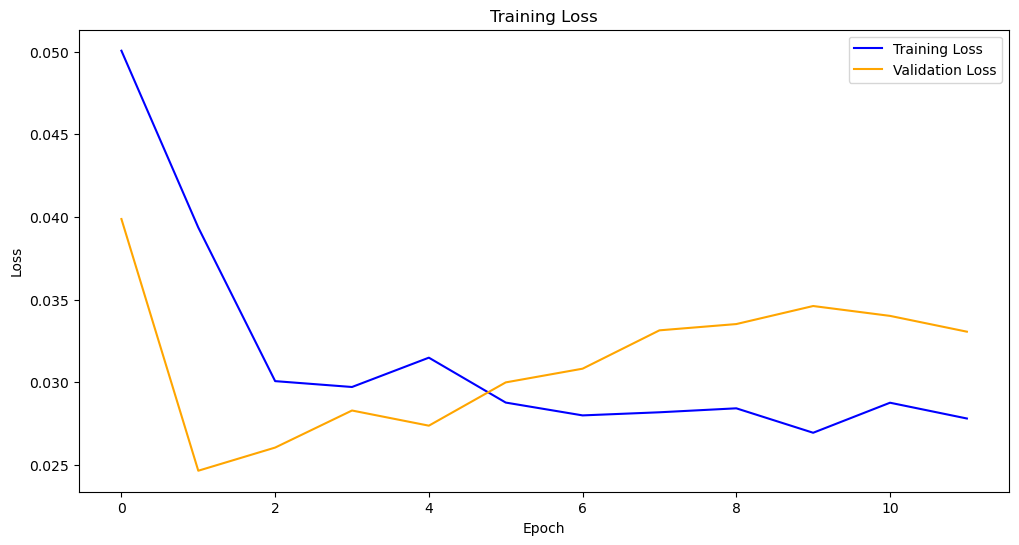

In [31]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(history4.history['loss'], label='Training Loss', color='blue')
ax.plot(history4.history['val_loss'], label='Validation Loss', color='orange')
ax.set_title('Training Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend()
plt.show()

This model also has a similar MAE to the longer lookback of model1, but is marginally beat out by the prior shorter lookback model.

Closing Thoughts;
I think that this problem can be reasonable predicted by an LSTM NN model. a MAE of >.5 is extremely good; however, this problem can always be solved better. The Idea was to find a predictor of precipitation for colorado, but I think what we learned from these models is that these is much more to the story than just the pacific ocean. To improve the predictions and the models, I think looking at atmospheric variables along with the pacific ocean features can lead to a better result just as a start, but a plethora of other methods could be used to futher improve this project into the future!